In [5]:
import torch

In [6]:
torch.cuda.is_available()

True

In [7]:
import cv2
import matplotlib.pyplot as plt

In [8]:
rgb=cv2.imread("set00/V000/visible/I00000.jpg")
thermal = cv2.imread("set00/V000/lwir/I00000.jpg", cv2.IMREAD_GRAYSCALE) #collapse to 1 channel as no real color even existed in ir image so using  cv2.imread_grayscale we just dropped useless channel

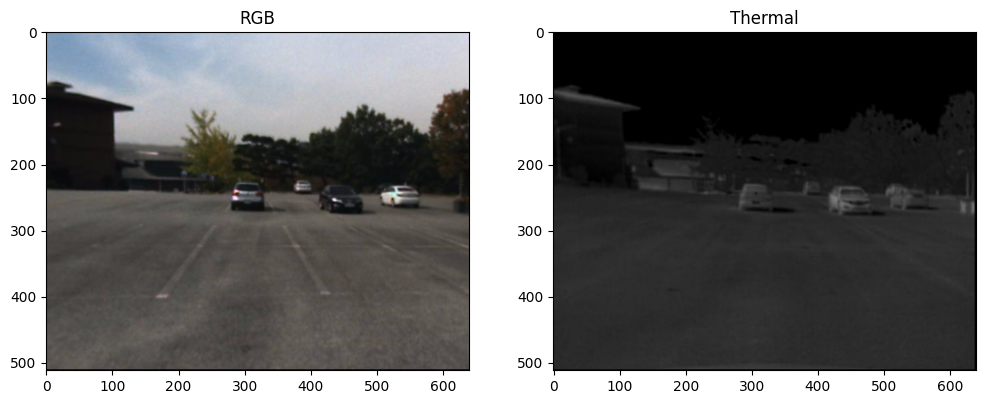

In [9]:
fig, axes=plt.subplots(1,2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB))
axes[0].set_title("RGB")
axes[1].imshow(cv2.cvtColor(thermal, cv2.COLOR_BGR2RGB))
axes[1].set_title("Thermal")
plt.show()



In [10]:
print(rgb.shape)

(512, 640, 3)


In [11]:
print(thermal.shape)

(512, 640)


In [12]:
def load_pair(set_folder, seq_folder, frame_id):
    rgb=cv2.imread(f"{set_folder}/{seq_folder}/visible/{frame_id}.jpg")
    thermal=cv2.imread(f"{set_folder}/{seq_folder}/lwir/{frame_id}.jpg", cv2.IMREAD_GRAYSCALE)
    if rgb is None or thermal is None:
        raise FileNotFoundError(f"couldn't load: {set_folder}/{seq_folder}/{frame_id}")
    return rgb, thermal

def show_pair(rgb, thermal, title=""):
    fig, axes=plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"RGB{title}")
    axes[1].imshow(thermal, cmap='gray')
    axes[1].set_title(f"Thermal{title}")
    plt.show()

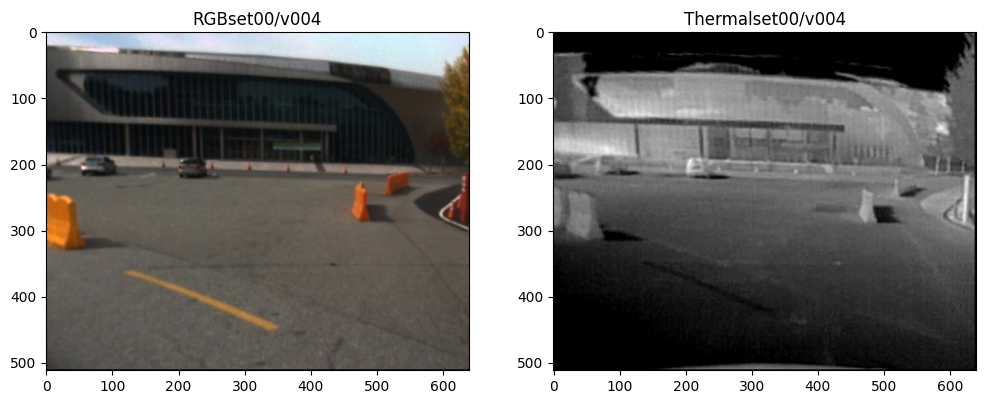

In [13]:
rgb1, th1=load_pair("set00", "v000", "I00500")
show_pair(rgb1, th1, "set00/v004")

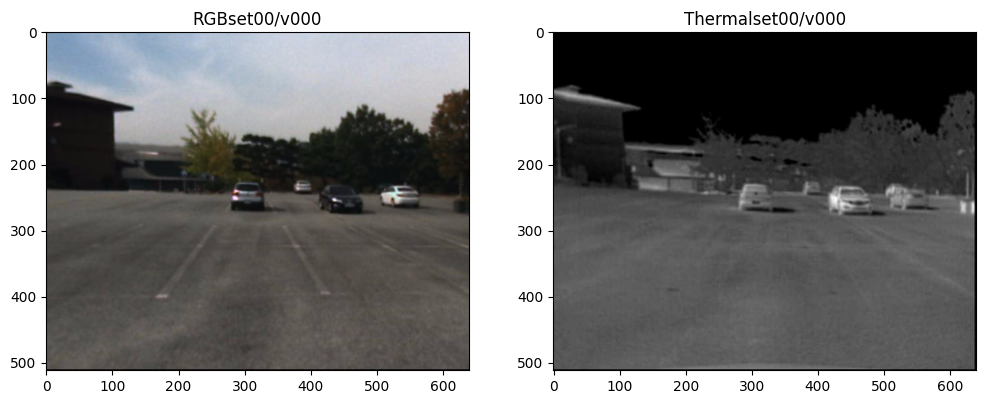

In [14]:
 rgb2, th2=load_pair("set00", "v000", "I00000")
 show_pair(rgb2, th2, "set00/v000")

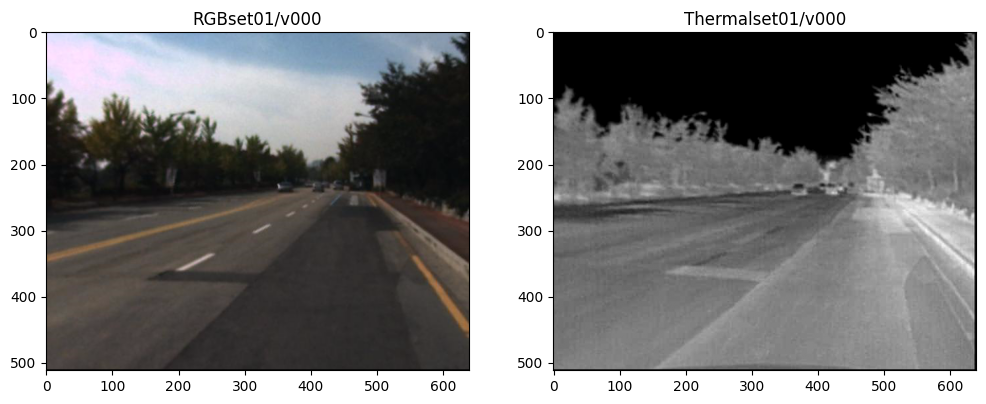

In [15]:
 rgb2, th2=load_pair("set01", "v000", "I00000")
 show_pair(rgb2, th2, "set01/v000") #set01/v000 is heading over each image that is being shown below

In [24]:
import os
from torch.utils.data import Dataset

class KAISTPairDataset(Dataset):
    def __init__(self, root_dir, set_folder, seq_folder):
        self.rgb_dir=f"{root_dir}/{set_folder}/{seq_folder}/visible"
        self.thermal_dir=f"{root_dir}/{set_folder}/{seq_folder}/lwir"
        self.frame_ids=sorted(os.listdir(self.rgb_dir)) # list all frame filenames once, so we know how many pairs exist
        # print(self.frame_ids)

    def __len__(self):
        #Pythorch needs this to know how many items total, e.g. for looping or batching
        return len(self.frame_ids)

    def __getitem__(self, idx):
        # pytorch calls this automatically when it wants item number 'idx'
        frame_name=self.frame_ids[idx]
        rgb=cv2.imread(f"{self.rgb_dir}/{frame_name}")
        thermal=cv2.imread(f"{self.thermal_dir}/{frame_name}", cv2.IMREAD_GRAYSCALE)

        if rgb is None or thermal is None:
            raise FileNotFoundError(f"couldn't load: {self.rgb_dir}/{frame_name}")
        return rgb, thermal



In [26]:
dataset=KAISTPairDataset(".", "set00", "v000")
print(len(dataset))
print(dataset)
rgb, thermal=dataset[0]
print(rgb.shape, thermal.shape)
print(len(dataset.frame_ids))

2245
(512, 640, 3) (512, 640)
2245


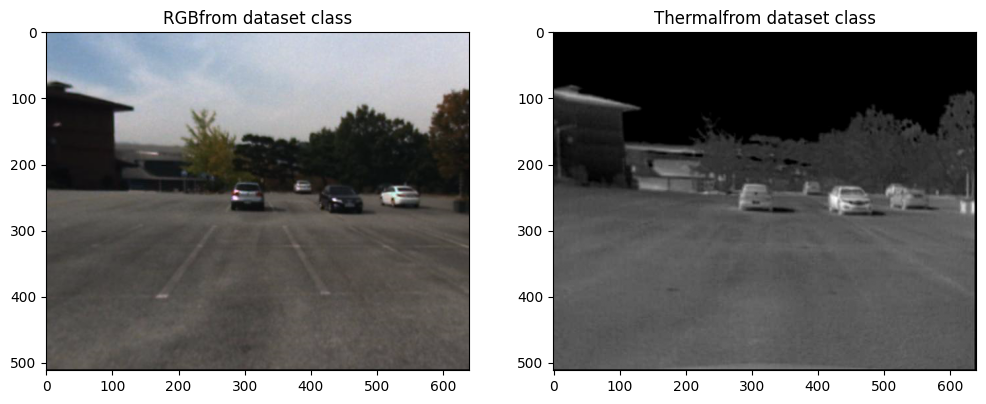

In [20]:
show_pair(rgb, thermal, "from dataset class")

In [28]:
# NOW WE ARE GONNA MODIFY THE KAISTDATASETCLASS THAT WE MADE EARLIER AND NOW GONNA ADD ALL IMAGEES PAIR IN A SINGLE TUPLE BY ITERATING THROUGH EACH FOLDER

class KAISTPairDataset(Dataset):
    def __init__(self, base_dir, set_folder, seq_folder):
        pass

In [31]:
# class KAISTDataset(Dataset):
#     def __init__(self, root_dir, set_folder, seq_folder):
#         self.rgb_dir=f"{root_dir}/{set_folder}/{seq_folder}/visible"
#         self.thermal_dir=f"{root_dir}/{set_folder}/{seq_folder}/lwir"
#         self.frame_ids=sorted(os.listdir(self.rgb_dir))
#     def __len__(self):
#         return len(self.frame_ids)
#     def __getitem__(self, idx):
#         frame_namee=self.frame_ids[idx]
#         rgb=cv2.imread(f"{self.rgb_dir}/{frame_namee}")
#         thermal=cv2.imread(f"{self.thermal_dir}/{frame_namee}")
#         if rgb is None or thermal is None:
#             raise FileNotFoundError(f"couldn't load: {self.rgb_dir}/{frame_namee}")
#         return rgb, thermal

In [37]:
class KAISTMultiSeqDataset(Dataset):
    def __init__(self, base_dir, set_folder, seq_folders):
        self.base_dir=base_dir
        self.set_folder=set_folder
        self.samples=[] # will hold (seq_folder, frame_filename) for every frame, across all sequences

        for seq_folder in seq_folders:
            rgb_dir =f"{base_dir}/{set_folder}/{seq_folder}/visible"
            frame_names=sorted(os.listdir(rgb_dir))
            for frame_name in frame_names:
                self.samples.append((seq_folder, frame_name))

    def __len__(self):
            return len(self.samples)

    def __getitem__(self, idx):
        seq_folder, frame_name=self.samples[idx]
        rgb_path=f"{self.base_dir}/{self.set_folder}/{seq_folder}/visible/{frame_name}"
        thermal_path=f"{self.base_dir}/{self.set_folder}/{seq_folder}/lwir/{frame_name}"
        rgb=cv2.imread(rgb_path)
        thermal=cv2.imread(thermal_path, cv2.IMREAD_GRAYSCALE)
        if rgb is None or thermal is None:
            raise FileNotFoundError(f"couldn't load: {rgb_path}")
        return rgb, thermal

4325


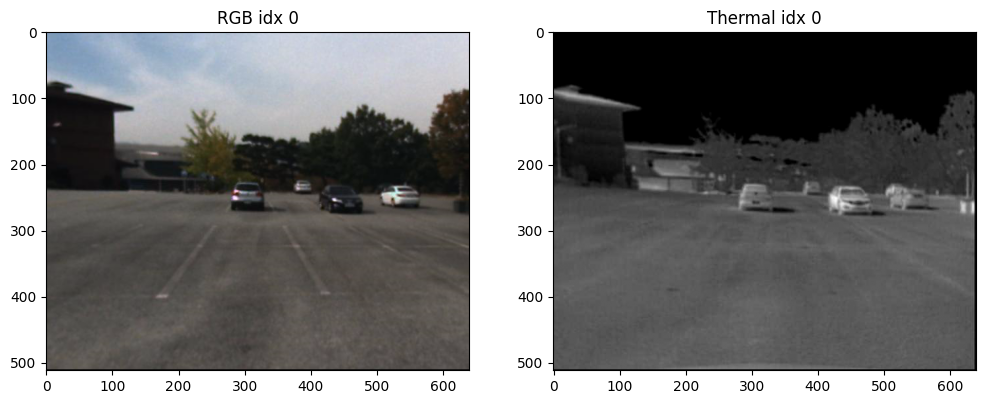

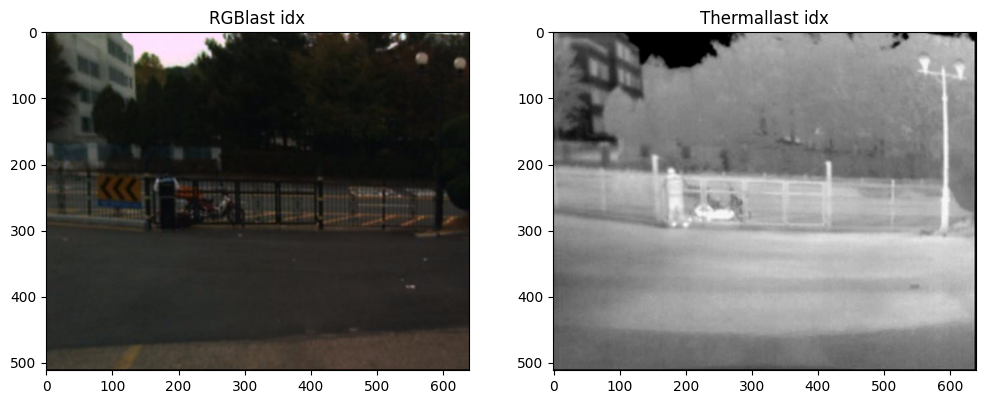

In [39]:
dataset=KAISTMultiSeqDataset(".", "set00", ["V000", "V004"])
print(len(dataset))
rgb, thermal=dataset[0]
show_pair(rgb, thermal, " idx 0")
rgb, thermal=dataset[len(dataset)-1]
show_pair(rgb, thermal, "last idx")

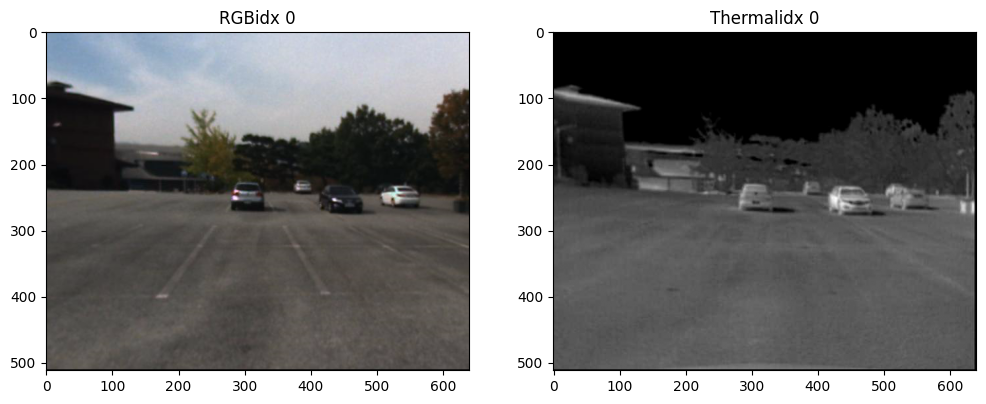

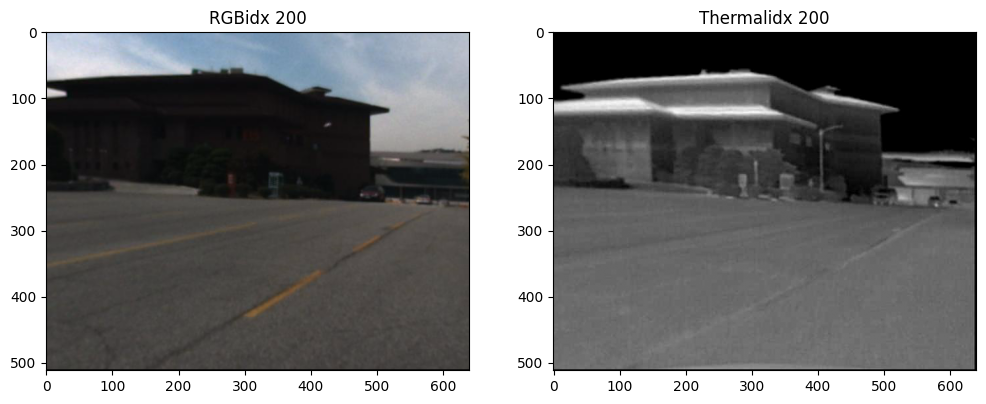

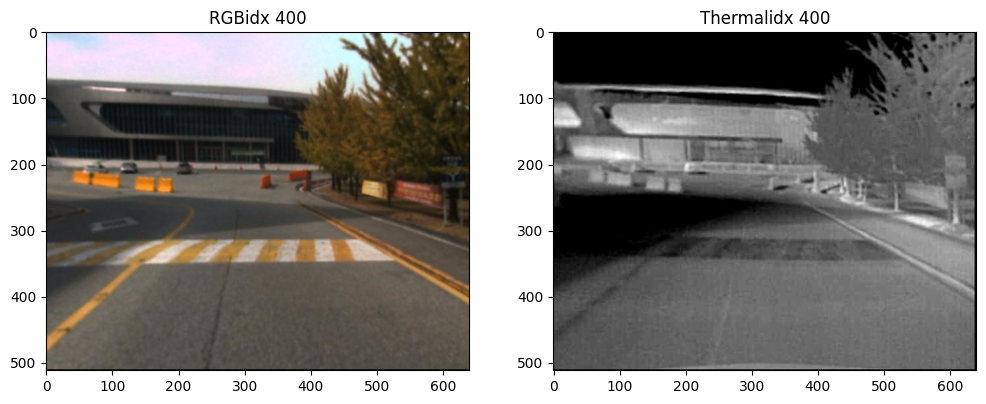

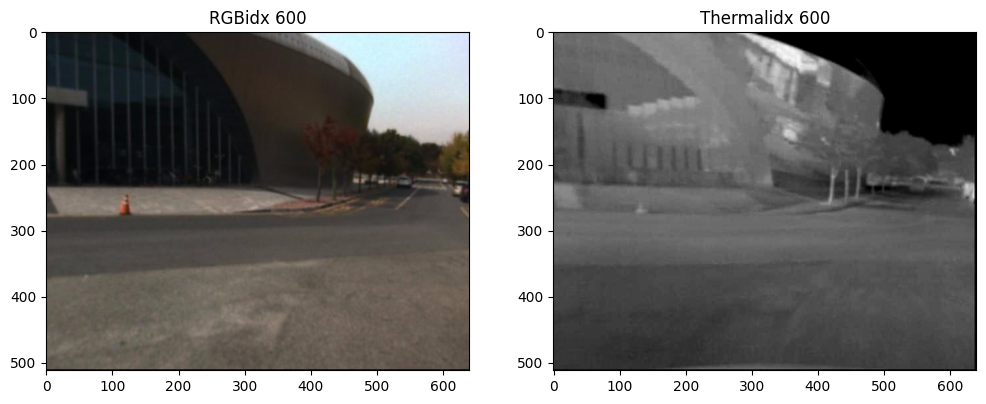

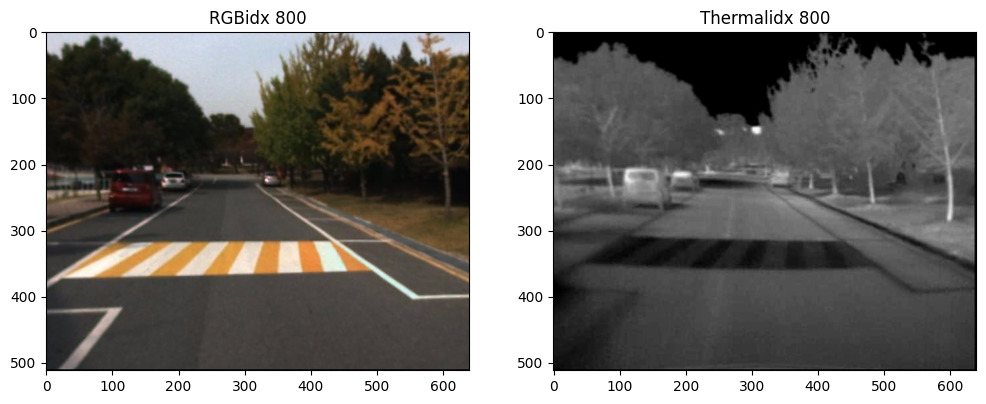

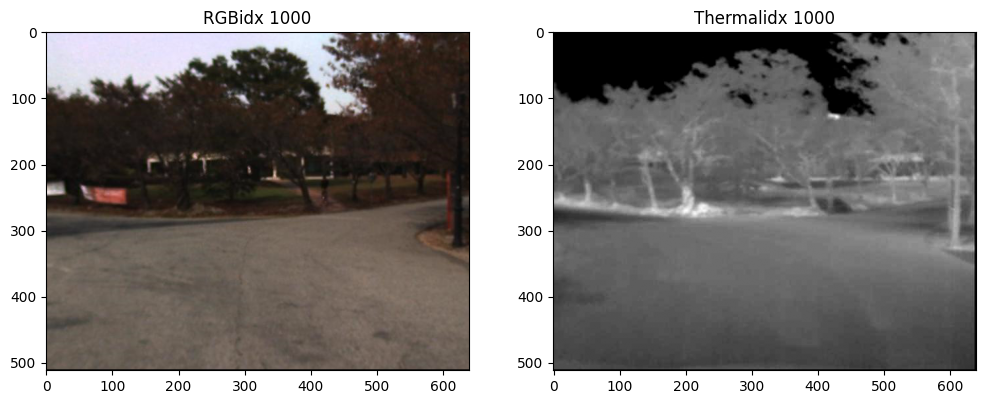

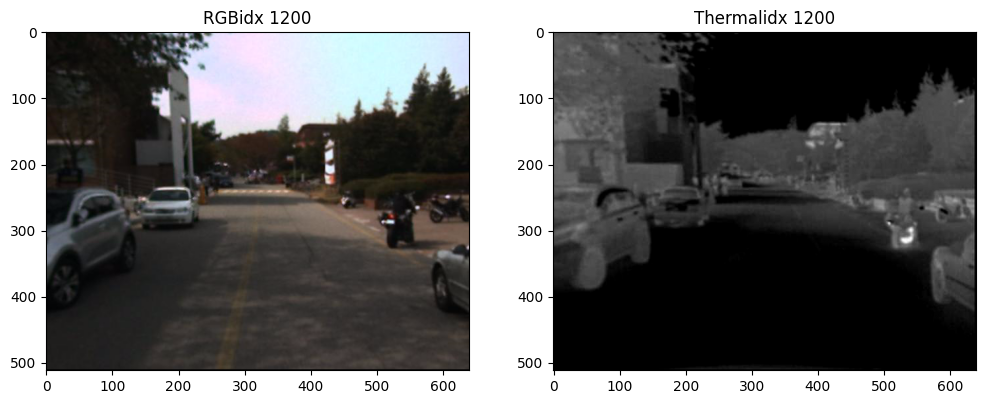

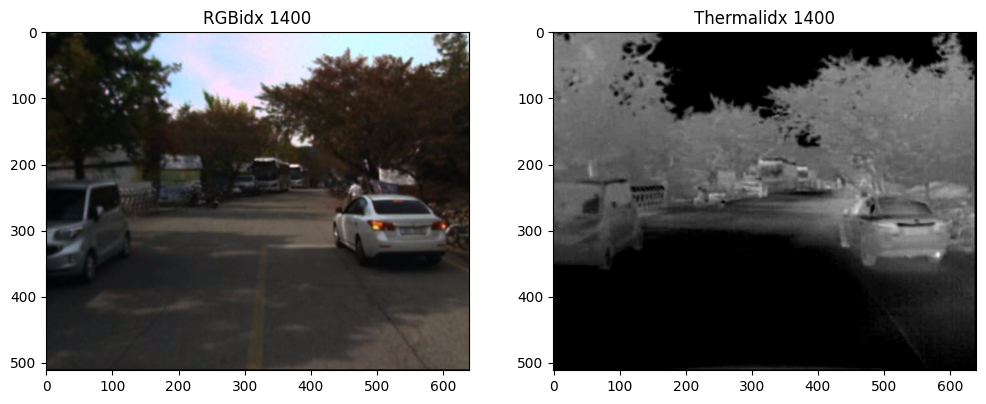

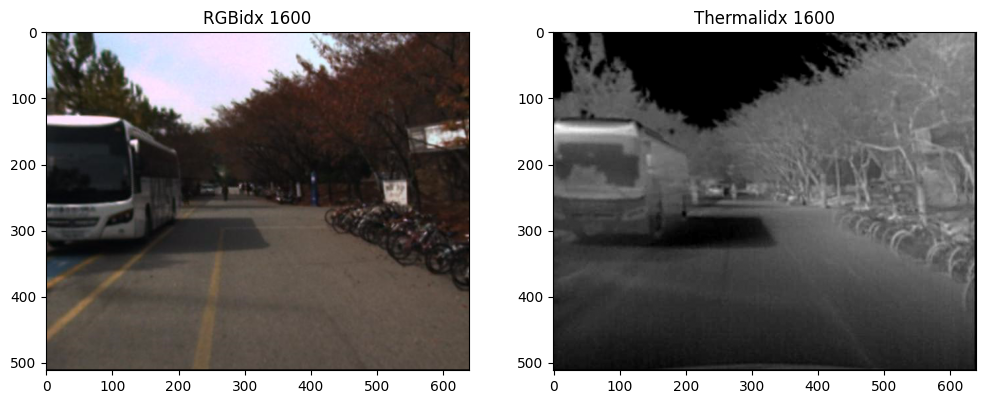

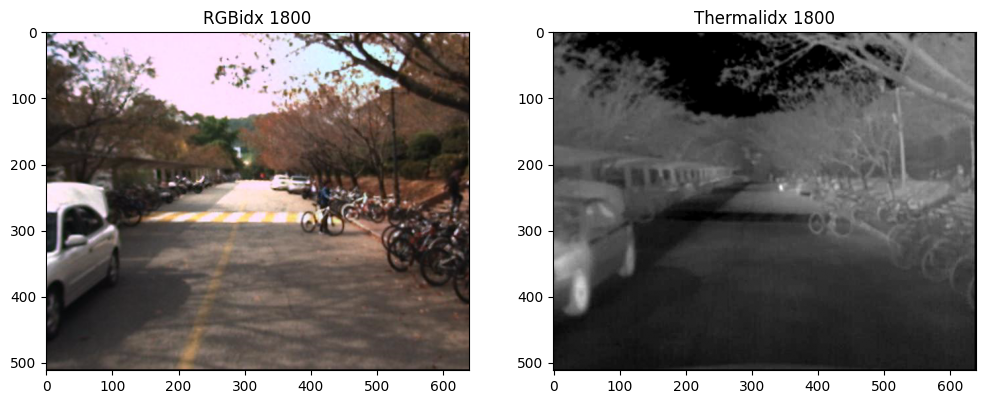

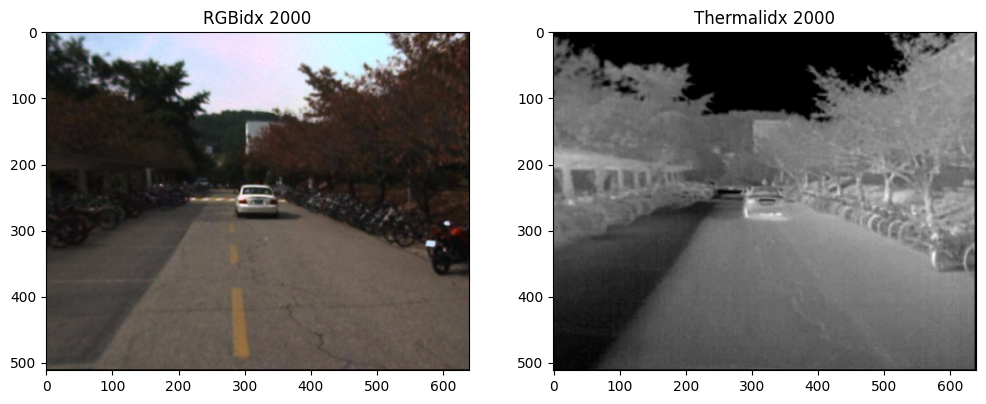

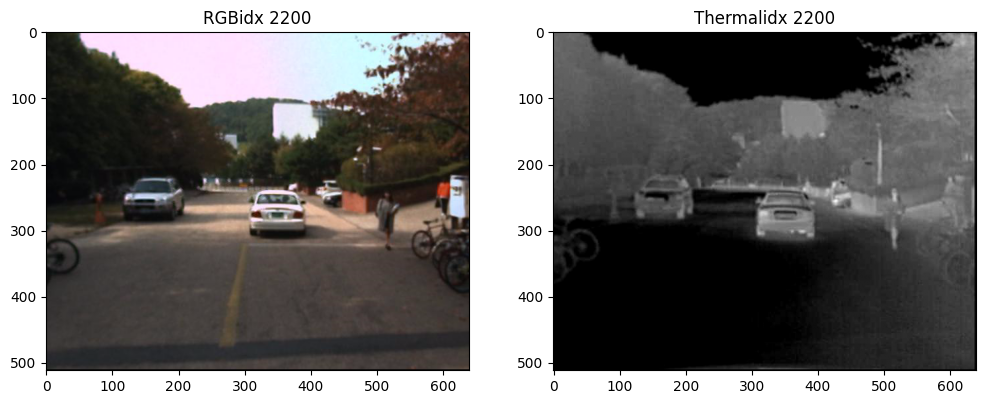

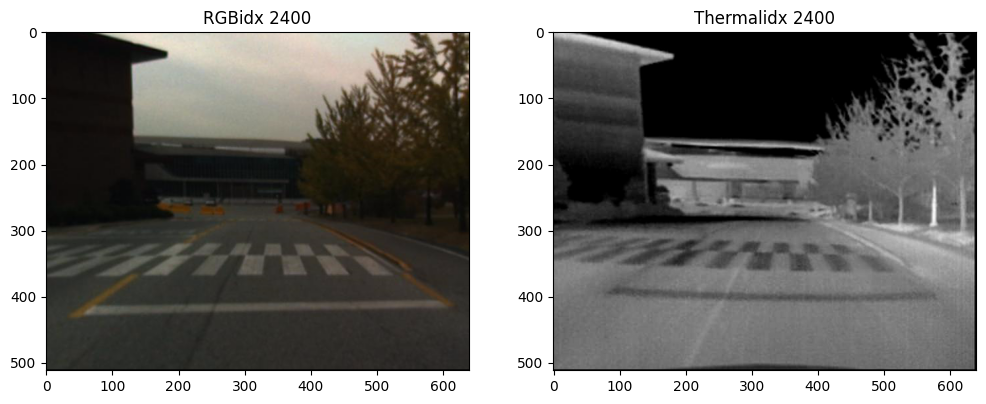

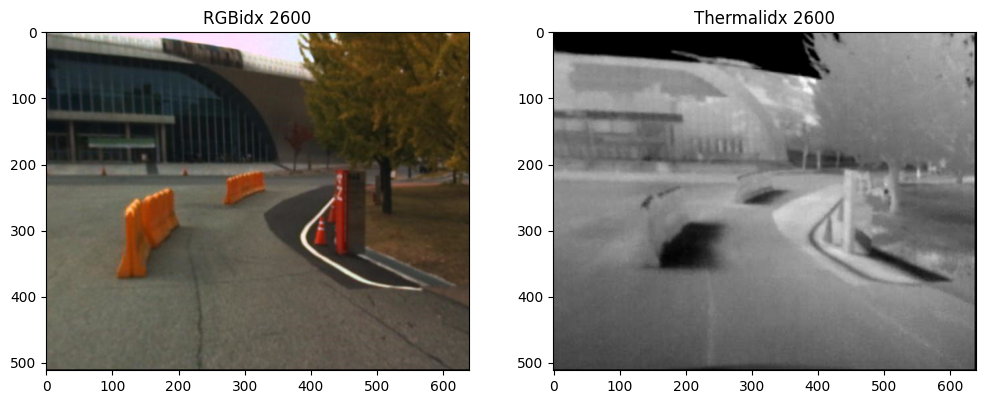

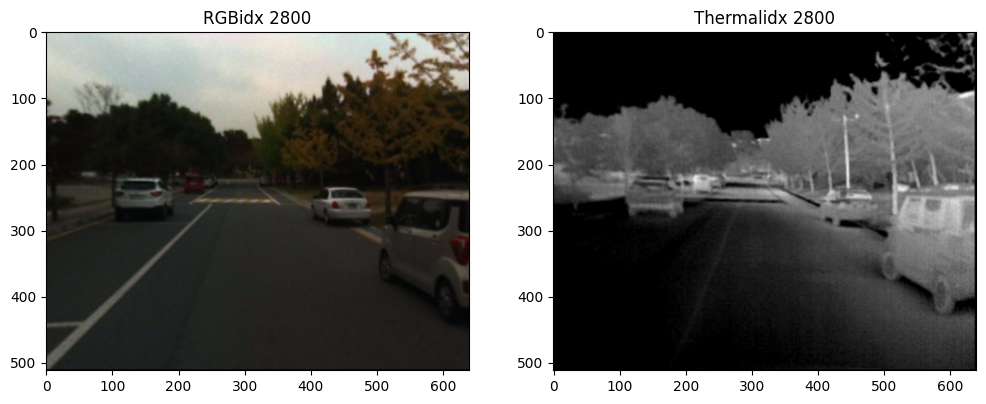

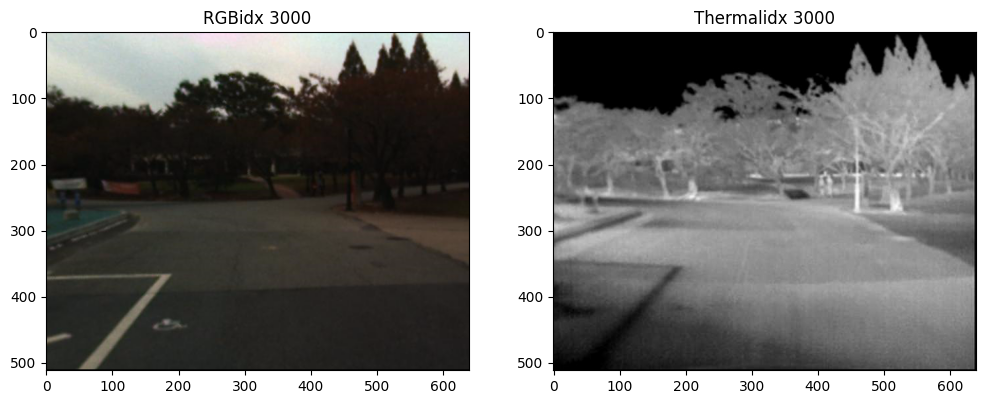

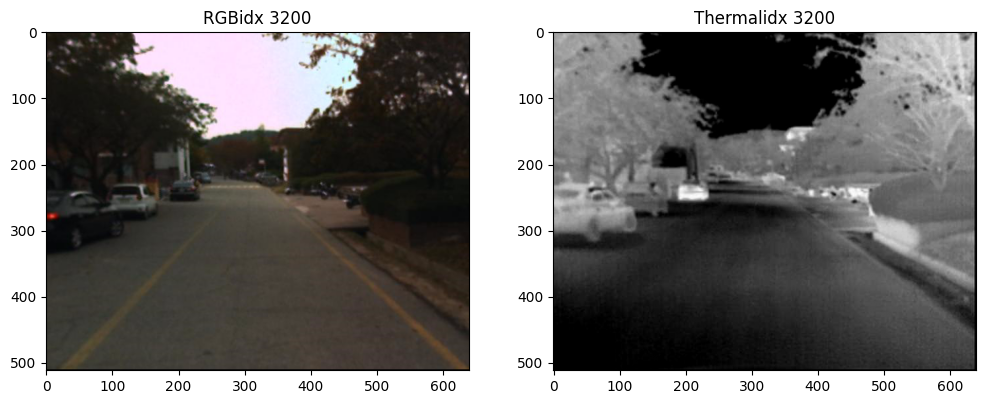

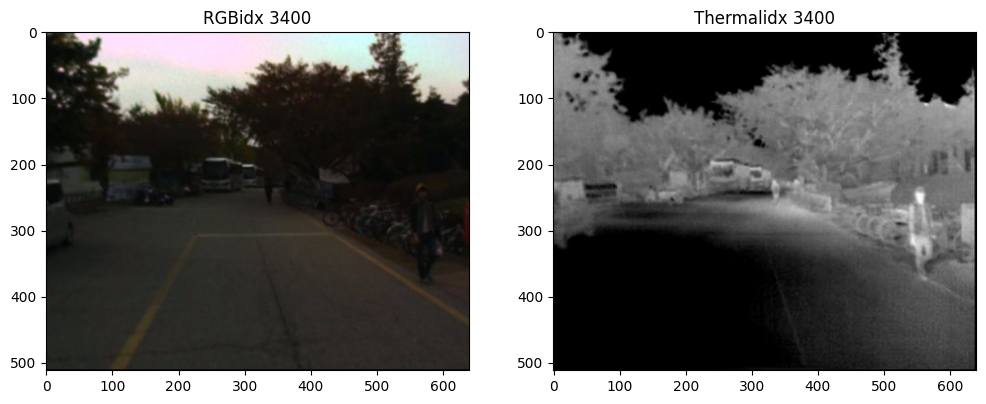

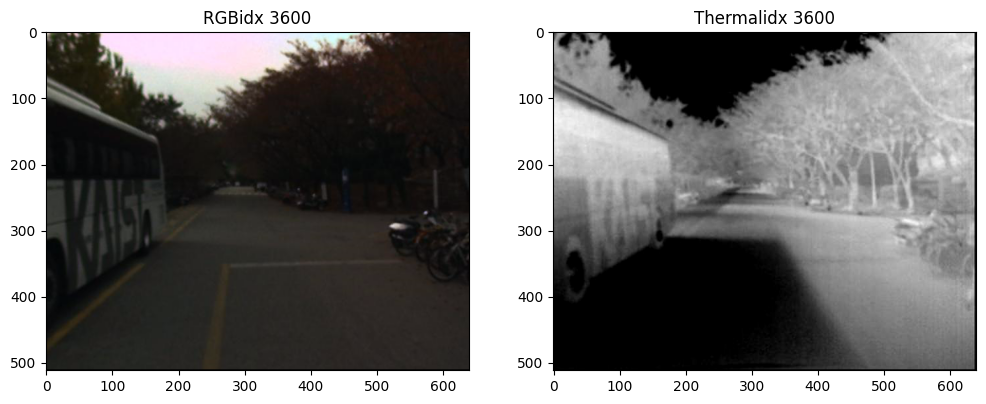

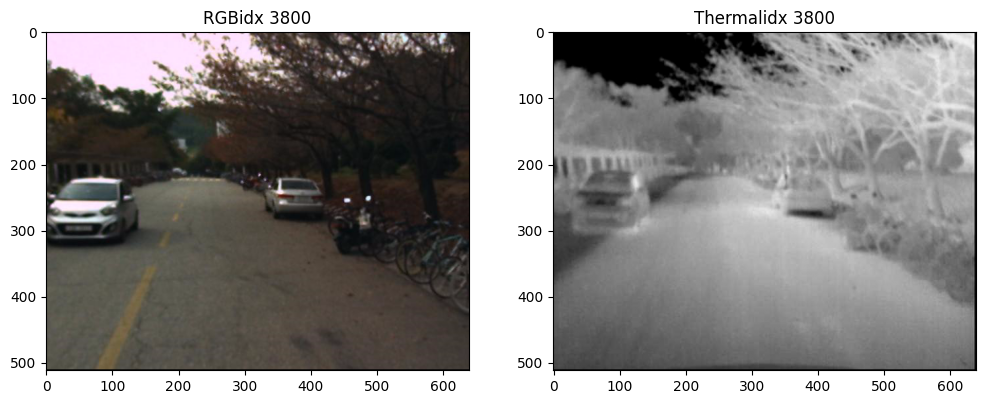

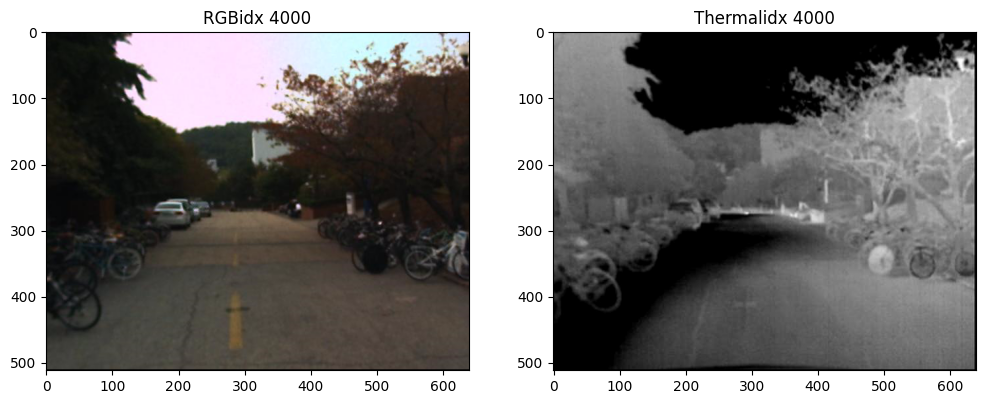

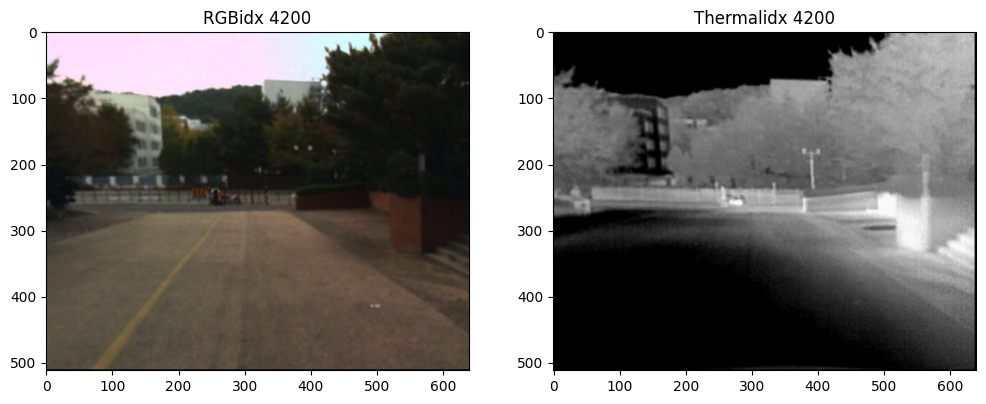

In [40]:
for i in range(0, len(dataset), 200):  # every 200th frame, adjust step as needed
    rgb, thermal = dataset[i]
    show_pair(rgb, thermal, f"idx {i}")